# Cathode overpotential breakdown

Decompose the cell overpotential into its contributions for four cases, all
compared at the same |j| = 2000 A/m² (not each test's own experimental
maximum, which differs per test) for a fair side-by-side breakdown:

- **Test 5** — discharge, SOC 10%
- **Test 16** — discharge, SOC 50%
- **Test 16** — charge, SOC 50%
- **Test 25** — charge, SOC 90%

All four share T = 32°C and Q_v = 45 ml/min; only SOC and current direction
differ, isolating their effect on the breakdown.

For each case the cell is run galvanostatically to steady state (or the SOC cut-off
event), and the converged state is decomposed into:

- Cathode **activation** overpotential ($\eta_{act}^{ca}$)
- Cathode **diffusion / concentration** overpotential ($\eta_{diff}^{ca}$)
- Cathode **Nernst / bulk-depletion** overpotential ($\eta_{Nernst}^{ca}$), i.e. the
  shift of the local equilibrium potential relative to the tank reservoir
- **Ohmic** overpotential, $\eta_{ohmic} = j \cdot \mathrm{HFR}$
- Anode (ACL) **activation** overpotential ($\eta_{act}^{an}$)
- ACL **protonic** overpotential ($\eta_{H^+}^{ACL}$)

**Workflow:** run all -> read the printed summary and plots.

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import membraneparams, cathodeparams, anodeparams

## Parameters

All four cases are run at the same |j| = 2000 A/m² (see above) rather than
each test's experimental maximum. Two independently-fitted parameter sets
are applied per test before simulating:

- **Membrane / HFR parameters** — per-test, from that test's own
  `fit_v2_test{N}_*.json` (sorption/desorption kinetics, `sf_D`, extra
  ohmic resistance).
- **Cathode / anode kinetics** — from the *global* fit
  `results/test fitting/global/global_k_ca_32.json`: one shared cathode
  rate constant `k_ca` across the full T=32°C test group (tests 2, 5, 8, 11,
  16, 19, 22, 25, 28), with a separate anode exchange current `j0_an` per
  test. This is the current, superseding calibration — not the older
  per-test-only `fit_e_cell_test{N}_*.json` files, which turned out to all
  share one stale k_ca left over from an earlier 3-test-only joint fit.

In [2]:
CASES = [
    {"test": 5,  "mode": "discharge", "label": "Test 5 - max discharge"},
    {"test": 16, "mode": "discharge", "label": "Test 16 - discharge"},
    {"test": 16, "mode": "charge",    "label": "Test 16 - charge"},
    {"test": 25, "mode": "charge",    "label": "Test 25 - max charge"},
]

TF   = 1800   # s, simulation horizon
RTOL = 1e-5

data_exp = pd.read_csv(ROOT / "data" / "experimental" / "HFR.csv")

## Run simulations

In [3]:
results = {}

# Global e-cell fit (shared k_ca across the T=32degC test group, per-test j0_an)
GLOBAL_FIT = ROOT / "results" / "test fitting" / "global" / "global_k_ca_32.json"
with open(GLOBAL_FIT) as f:
    _global = json.load(f)
K_CA_GLOBAL  = _global["params"]["k_ca"]
J0_AN_GLOBAL = {int(k): v for k, v in _global["params"]["j0_an"].items()}
print(f"Global fit: {GLOBAL_FIT.name}  k_ca={K_CA_GLOBAL:.4e} m/s  "
      f"(tests {_global['tests']})")

for case in CASES:
    test_no, mode = case["test"], case["mode"]
    print(f"\n=== {case['label']} ===")

    d   = data_exp[data_exp["test_no"] == test_no]
    soc = d["SOC"].iloc[0]
    T   = d["T(°C)"].iloc[0]
    Q_v = d["Q_v (ml/min)"].iloc[0]

    # Same |j| for every case, for a fair side-by-side breakdown (not each
    # test's own experimental maximum -- see markdown above).
    j_appl = 2000.0 if mode == "charge" else -2000.0

    print(f"  SOC={soc}, T={T} degC, Q_v={Q_v} ml/min, j_appl={j_appl:+.1f} A/m2")

    # -- fitted parameters --------------------------------------------------
    fit_dir = ROOT / "results" / "test fitting" / f"test {test_no}"
    hfr_fit = sorted(fit_dir.glob(f"fit_v2_test{test_no}_*.json"))[-1]

    with open(hfr_fit) as f:
        fit = json.load(f)
    p, s = fit["params"], fit["settings"]
    membraneparams.k_sorp_vw   = p["k_vw_sorp"]
    membraneparams.k_desorp_vw = p["S_desorp"] * p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = p["k_lw_sorp"]
    membraneparams.k_desorp_lw = p["S_desorp"] * p["k_lw_sorp"]
    membraneparams.k_ca_lw     = p["k_ca"]
    membraneparams.sf_D        = s["sf_D"]
    R_extra = [v for k, v in p.items() if k.startswith("R_extra")][0] / 1e4  # Ohm.cm2 -> Ohm.m2

    cathodeparams.reaction_rate_constant = K_CA_GLOBAL
    anodeparams.j_0                      = J0_AN_GLOBAL[test_no]

    # -- run to steady state -------------------------------------------------
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol         = build_atol(cell)
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)

    t0  = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    print(f"  t_final={sol.t[-1]:.1f} s  ({time.time()-t0:.1f} s wall)")

    y_final, yp_final = sol.y[:, -1], sol.yp[:, -1]
    cell.dae_residual_full_cell(sol.t[-1], y_final, yp_final)  # refresh cell.eta_proton etc.

    results[test_no, mode] = dict(case=case, mode=mode, cell=cell, y=y_final, j_appl=j_appl, R_extra=R_extra)

Global fit: global_k_ca_32.json  k_ca=1.6746e-07 m/s  (tests [2, 5, 8, 11, 16, 19, 22, 25, 28])

=== Test 5 - max discharge ===
  SOC=0.1, T=32 degC, Q_v=45 ml/min, j_appl=-2000.0 A/m2
  t_final=1800.0 s  (3.4 s wall)

=== Test 16 - discharge ===
  SOC=0.5, T=32 degC, Q_v=45 ml/min, j_appl=-2000.0 A/m2
  t_final=1800.0 s  (2.1 s wall)

=== Test 16 - charge ===
  SOC=0.5, T=32 degC, Q_v=45 ml/min, j_appl=+2000.0 A/m2
  t_final=1800.0 s  (10.8 s wall)

=== Test 25 - max charge ===
  SOC=0.9, T=32 degC, Q_v=45 ml/min, j_appl=+2000.0 A/m2
  t_final=1800.0 s  (18.5 s wall)


## Overpotential decomposition

`cell.decompose_overpotential` returns the local activation, diffusion and
Nernst overpotentials at every cathode node. The scalar summary values used
in the bar chart below are current-weighted averages, using the local
Butler-Volmer volumetric current density as the weight (so nodes that carry
more current contribute more to the average).

In [4]:
breakdown = {}

for test_no, r in results.items():
    cell, y, j_appl, R_extra = r["cell"], r["y"], r["j_appl"], r["R_extra"]
    mode   = r["mode"]
    state  = cell.split_state(y)
    decomp = cell.decompose_overpotential(y)

    # -- current-weighted average of the cathode contributions ----------------
    c_eta = np.concatenate([state["cathode"][:, 0], state["cathode"][:, 1], state["cathode"][:, 2]])
    BV    = cell.butler_volmer(decomp["eta_total"], c_eta, "cathode")
    dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    w     = np.abs(BV * dx_ca)

    eta_ca        = np.sum(decomp["eta_total"]   * w) / w.sum()

    # -- ohmic overpotential, eta_ohmic = j * HFR ------------------------------
    sigma_ca  = cell.cathode.eff_conductivity
    kappa_ca  = cell.cathode.kappa_io
    R_cathode = np.sum(dx_ca / (sigma_ca + kappa_ca))

    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = np.sum(dx_m / cell.membrane.kappa_io)

    R_ACL  = cell.anode.thickness / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness  / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC
    HFR    = R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + R_extra  # Ohm.m2

    eta_ohmic = j_appl * HFR

    # -- anode (ACL) activation overpotential ----------------------------------
    eta_anode = state["anode"][3]

    # -- ACL protonic overpotential --------------------------------------------
    eta_acl_proton = cell.eta_proton

    breakdown[test_no] = dict(
        label=r["case"]["label"], j_appl=j_appl, mode=mode,  decomp=decomp,
        eta_ca=eta_ca,
        eta_ohmic=eta_ohmic, eta_anode=eta_anode, eta_acl_proton=eta_acl_proton,
        HFR=HFR,
    )

    print(f"\n{r['case']['label']}  (j_appl = {j_appl:+.1f} A/m2, HFR = {HFR*1e4:.3f} Ohm.cm2)")
    print(f"  Cathode overpotential  eta_act    = {eta_ca*1e3:+8.2f} mV")
    print(f"  Ohmic (I x HFR)        eta_ohmic  = {eta_ohmic*1e3:+8.2f} mV")
    print(f"  Anode (ACL) overpotential eta_anode  = {eta_anode*1e3:+8.2f} mV")
    print(f"  ACL protonic           eta_H+     = {eta_acl_proton*1e3:+8.2f} mV")



Test 5 - max discharge  (j_appl = -2000.0 A/m2, HFR = 0.934 Ohm.cm2)
  Cathode overpotential  eta_act    =   -91.34 mV
  Ohmic (I x HFR)        eta_ohmic  =  -186.88 mV
  Anode (ACL) overpotential eta_anode  =    +6.32 mV
  ACL protonic           eta_H+     =   +33.27 mV

Test 16 - discharge  (j_appl = -2000.0 A/m2, HFR = 0.586 Ohm.cm2)
  Cathode overpotential  eta_act    =   -43.37 mV
  Ohmic (I x HFR)        eta_ohmic  =  -117.12 mV
  Anode (ACL) overpotential eta_anode  =    +5.33 mV
  ACL protonic           eta_H+     =   +15.72 mV

Test 16 - charge  (j_appl = +2000.0 A/m2, HFR = 0.458 Ohm.cm2)
  Cathode overpotential  eta_act    =   +49.42 mV
  Ohmic (I x HFR)        eta_ohmic  =   +91.54 mV
  Anode (ACL) overpotential eta_anode  =    -5.33 mV
  ACL protonic           eta_H+     =    -8.21 mV

Test 25 - max charge  (j_appl = +2000.0 A/m2, HFR = 0.531 Ohm.cm2)
  Cathode overpotential  eta_act    =  +143.92 mV
  Ohmic (I x HFR)        eta_ohmic  =  +106.17 mV
  Anode (ACL) overpote

## Overpotential breakdown


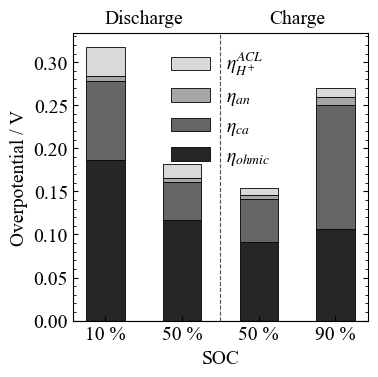

In [5]:
# -- Elsevier-style formatting ----------------------------------------------
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times'],
    'mathtext.fontset': 'stix',
    'font.size': 14,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
})

# x-axis categories = SOC only
components = ["10 %", "50 %", "50 %", "90 %"]

eta_comp = {
    r'$\eta_{ohmic}$':     abs(np.array([breakdown[t]["eta_ohmic"]      for t in breakdown])),
    r'$\eta_{ca}$':        abs(np.array([breakdown[t]["eta_ca"]         for t in breakdown])),
    r'$\eta_{an}$':  abs(np.array([breakdown[t]["eta_anode"]      for t in breakdown])),
    r'$\eta_{H^+}^{ACL}$': abs(np.array([breakdown[t]["eta_acl_proton"] for t in breakdown])),
}

grays = ['0.15', '0.4', '0.65', '0.85']

x_pos = np.arange(len(components))
width = 0.5

fig, ax = plt.subplots(figsize=(4, 4))  # double-column width, ~190 mm
bottom = np.zeros(len(components))

for (label, values), gray in zip(eta_comp.items(), grays):
    ax.bar(x_pos, values, width, bottom=bottom, label=label,
           color=gray, edgecolor='black', linewidth=0.6)
    bottom += values

ax.axhline(0, color='0.3', lw=0.8, zorder=0)
ax.set_xticks(x_pos)
ax.set_xticklabels(components)
ax.set_xlabel('SOC')
ax.set_ylabel('Overpotential / V')

ax.axvline(1.5, color='0.3', ls='--', lw=0.8, zorder=0)
ax.text(0.5, 1.02, 'Discharge', ha='center', va='bottom',
        transform=ax.get_xaxis_transform())
ax.text(2.5, 1.02, 'Charge', ha='center', va='bottom',
        transform=ax.get_xaxis_transform())

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False)
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.tick_params(which='both', direction='in', right=True)

plt.tight_layout()
out_path = ROOT / "figures/overpotential_breakdown.pdf"
plt.savefig(out_path, bbox_inches='tight')
plt.show()

## Pore-level Damkohler number

$Da = k_{ca} / \beta_0$

In [6]:
case_colors = {
    (5,  "discharge"): "#b2182b",   # deep red    (extreme: SOC 10%)
    (16, "discharge"): "#ef8a62",   # light red   (mid: SOC 50%)
    (16, "charge"):    "#67a9cf",   # light blue  (mid: SOC 50%)
    (25, "charge"):    "#2166ac",   # deep blue   (extreme: SOC 90%)
}

_cases_da = [
    (5,  "discharge", "Test 5  – SOC 10 % dis"),
    (16, "discharge", "Test 16 – SOC 50 % dis"),
    (16, "charge",    "Test 16 – SOC 50 % ch"),
    (25, "charge",    "Test 25 – SOC 90 % ch"),
]

da_labels, da_values, da_colors = [], [], []
print("Da for pore level:")
for test_no, mode, label in _cases_da:
    cell    = results[test_no, mode]["cell"]
    k_ca    = cell.cathode.reaction_rate_constant
    beta_0  = breakdown[test_no, mode]["decomp"]["beta_0"]
    Da      = k_ca / beta_0
    da_labels.append(label)
    da_values.append(Da)
    da_colors.append(case_colors[(test_no, mode)])
    print(f"{label:24s}  k_ca={k_ca:.4e} m/s   beta_0={beta_0:.4e} m/s   Da={Da:.4f}")

print("Da for electrode level")
for test_no, mode, label in _cases_da:
    cell    = results[test_no, mode]["cell"]
    k_ca    = cell.cathode.reaction_rate_constant
    L_ca    = cell.cathode.thickness
    D_V5    = cell.cathode.D_V5_eff
    Da      = k_ca * L_ca**2  / D_V5
    print(f"{label:24s}  k_ca={k_ca:.4e} m/s   D_V5={D_V5:.4e} m²/s   L_ca={L_ca:.4e} m   Da={Da:.4f}")


Da for pore level:
Test 5  – SOC 10 % dis    k_ca=1.6746e-07 m/s   beta_0=3.0278e-05 m/s   Da=0.0055
Test 16 – SOC 50 % dis    k_ca=1.6746e-07 m/s   beta_0=3.0278e-05 m/s   Da=0.0055
Test 16 – SOC 50 % ch     k_ca=1.6746e-07 m/s   beta_0=3.0278e-05 m/s   Da=0.0055
Test 25 – SOC 90 % ch     k_ca=1.6746e-07 m/s   beta_0=3.0278e-05 m/s   Da=0.0055
Da for electrode level
Test 5  – SOC 10 % dis    k_ca=1.6746e-07 m/s   D_V5=3.5543e-10 m²/s   L_ca=4.6000e-03 m   Da=0.0100
Test 16 – SOC 50 % dis    k_ca=1.6746e-07 m/s   D_V5=3.5543e-10 m²/s   L_ca=4.6000e-03 m   Da=0.0100
Test 16 – SOC 50 % ch     k_ca=1.6746e-07 m/s   D_V5=3.5543e-10 m²/s   L_ca=4.6000e-03 m   Da=0.0100
Test 25 – SOC 90 % ch     k_ca=1.6746e-07 m/s   D_V5=3.5543e-10 m²/s   L_ca=4.6000e-03 m   Da=0.0100


## Local Psi


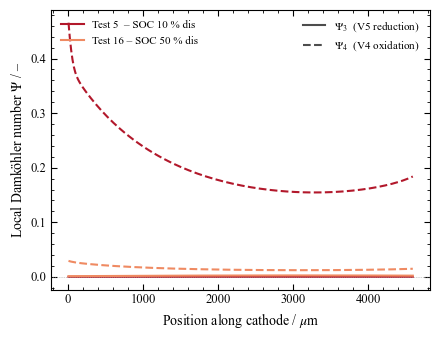

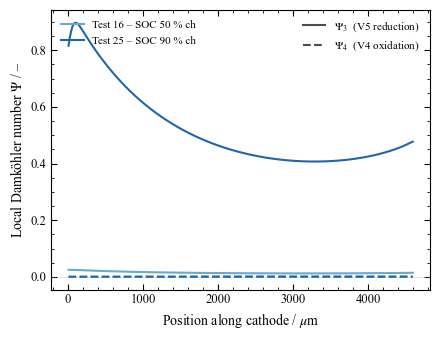

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
import numpy as np

# Paper style — set once
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['STIX', 'Times New Roman', 'Times'],
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Split the cases into the two regimes
discharge_cases = [c for c in _cases_da if c[1] == "discharge" and c[0] in (5, 16)]
charge_cases    = [c for c in _cases_da if c[1] == "charge"    and c[0] in (16, 25)]

def plot_psi_panel(cases, save_path, panel_title=None):
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    legend_handles, legend_labels = [], []

    for test_no, mode, label in cases:
        col    = case_colors[(test_no, mode)]
        cell   = results[test_no, mode]["cell"]
        decomp = breakdown[test_no, mode]["decomp"]
        j_appl = results[test_no, mode]["j_appl"]

        dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
        x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6

        (l_ref,) = ax.plot(x_um, decomp["Psi3"], color=col, lw=1.5, ls="-")
        ax.plot(x_um, decomp["Psi4"], color=col, lw=1.5, ls="--")

        legend_handles.append(l_ref)
        legend_labels.append(f"{label} ")

    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    ax.set_xlabel(r"Position along cathode / $\mu$m")
    ax.set_ylabel(r"Local Damköhler number $\Psi$ / –")

    case_legend = ax.legend(legend_handles, legend_labels, frameon=False, loc="upper left")
    ax.add_artist(case_legend)
    style_handles = [
        Line2D([0], [0], color="0.3", lw=1.5, ls="-",  label=r"$\Psi_3$  (V5 reduction)"),
        Line2D([0], [0], color="0.3", lw=1.5, ls="--", label=r"$\Psi_4$  (V4 oxidation)"),
    ]
    ax.legend(handles=style_handles, frameon=False, loc="upper right")

    fig.tight_layout()
    #fig.savefig(save_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
    plt.show()
    #print(f"Saved -> {save_path}")

# Panel (a): Discharge at low/intermediate SOC
plot_psi_panel(
    discharge_cases,
    ROOT / "figures/damkohler_profile_discharge.pdf",
)

# Panel (b): Charge at intermediate/high SOC
plot_psi_panel(
    charge_cases,
    ROOT / "figures/damkohler_profile_charge.pdf",
)

## Cathode overpotential, species concentrations, and exchange current density

Three separate plots -- local overpotential $\eta_{ca}$, bulk concentrations of
V(IV)/V(V)/H$^+$, and the exchange current density
$i_0 = F\,k_{ca}\,c_{V(V)}^{\alpha}\,c_{V(IV)}^{1-\alpha}$ (used in the
Butler-Volmer equation) -- each plotted along the cathode thickness for two pairs
of operating points sharing the same mode: discharge (SOC 10% vs 50%) and charge
(SOC 50% vs 90%).


In [ ]:
_discharge_pair = [(5,  "discharge", "Test 5 – SOC 10%"),
                    (16, "discharge", "Test 16 – SOC 50%")]
_charge_pair    = [(16, "charge",    "Test 16 – SOC 50%"),
                    (25, "charge",   "Test 25 – SOC 90%")]
_pairs = [("Discharge: SOC 10% vs 50%", _discharge_pair),
          ("Charge: SOC 50% vs 90%",    _charge_pair)]

def _cathode_profile_data(test_no, mode):
    """Bulk cathode species, local overpotential, exchange current density i_0,
    and the dimensionless Wagner-type numbers nu_sq / delta along the cathode
    thickness for one converged (test_no, mode) case."""
    r      = results[test_no, mode]
    cell   = r["cell"]
    j_appl = r["j_appl"]
    decomp = breakdown[test_no, mode]["decomp"]
    state  = cell.split_state(r["y"])
    cath   = state["cathode"]
    c_V4_ca, c_V5_ca, c_H_ca = cath[:, 0], cath[:, 1], cath[:, 2]

    dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6

    # Same regularised bulk concentrations used inside butler_volmer()'s i_0 term.
    eps   = 1e-4
    c_V4b = np.sqrt(np.maximum(c_V4_ca, 0)**2 + eps**2)
    c_V5b = np.sqrt(np.maximum(c_V5_ca, 0)**2 + eps**2)
    c_Hb  = np.sqrt(np.maximum(c_H_ca, 0)**2 + eps**2)
    alpha_c = cell.alpha_c
    k_ca  = cell.cathode.reaction_rate_constant
    F, R, T = cell.F, cell.R, cell.T
    i_0   = F * k_ca * (c_V5b**alpha_c) * (c_V4b**(1 - alpha_c))
    a     = cell.cathode.specific_surface_area  # specific surface area [m²/m³]

    # -- effective transport properties & geometry -----------------------------
    kappa = cell.cathode.kappa_io          # effective ionic conductivity [S/m], per node
    sigma = cell.cathode.eff_conductivity  # effective electronic conductivity [S/m]
    L     = cell.cathode.thickness         # cathode thickness [m]

    nu_sq = (1) * F * a * i_0 * L**2 / (R * T) * (1 / kappa + 1 / sigma)
    delta = -alpha_c * F * j_appl * L / (R * T) * (1 / kappa + 1 / sigma)

    return dict(x_um=x_um, eta=decomp["eta_total"], c_V4=c_V4_ca, c_V5=c_V5_ca,
                c_H=c_H_ca, i_0=i_0, nu_sq=nu_sq, delta=delta, j_appl=j_appl, kappa_io=kappa)

def _fname_suffix(title):
    return "discharge" if "Discharge" in title else "charge"


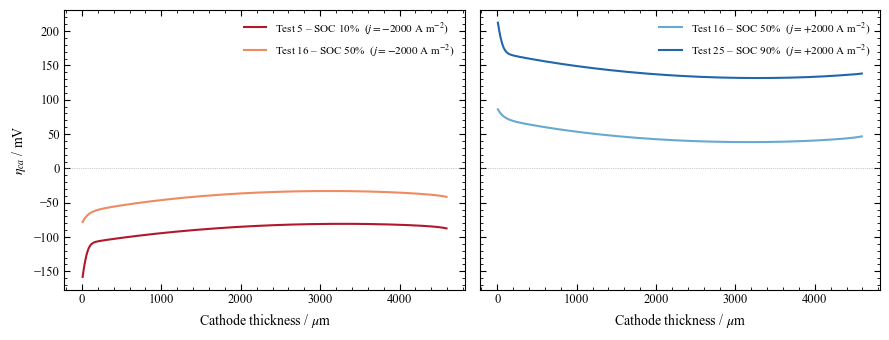

Saved -> C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D\figures\cathode_eta.pdf


In [9]:
# -- Cathode overpotential -------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

for ax, (title, cases) in zip(axes, _pairs):
    for test_no, mode, label in cases:
        d = _cathode_profile_data(test_no, mode)
        ax.plot(d["x_um"], d["eta"] * 1e3,
                color=case_colors[(test_no, mode)], lw=1.5,
                label=f"{label}  ($j={d['j_appl']:+.0f}$ A m$^{{-2}}$)")

    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    ax.set_xlabel(r"Cathode thickness / $\mu$m")
    ax.legend(frameon=False, loc="best")

axes[0].set_ylabel(r"$\eta_{ca}$ / mV")

fig.tight_layout()
out_path = ROOT / "figures" / "cathode_eta.pdf"
fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()
print(f"Saved -> {out_path}")


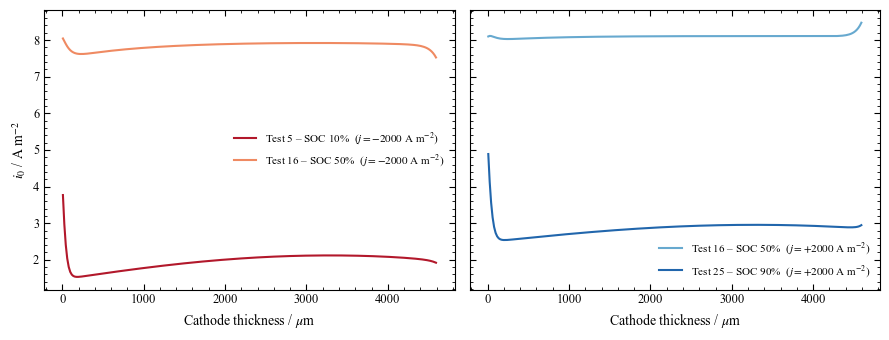

In [10]:
# -- Exchange current density i_0 --------------------------------------------------
import matplotlib.pyplot as plt
from matplotlib import ticker

# Paper style — set once
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['STIX', 'Times New Roman', 'Times'],
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

for ax, (title, cases) in zip(axes, _pairs):
    for test_no, mode, label in cases:
        d = _cathode_profile_data(test_no, mode)
        ax.plot(d["x_um"], d["i_0"],
                color=case_colors[(test_no, mode)], lw=1.5,
                label=f"{label}  ($j={d['j_appl']:+.0f}$ A m$^{{-2}}$)")

    ax.set_xlabel(r"Cathode thickness / $\mu$m")
    ax.legend(frameon=False, loc="best")

axes[0].set_ylabel(r"$i_0$ / A m$^{-2}$")

fig.tight_layout()
out_path = ROOT / "figures" / "cathode_i0.pdf"
#fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()
#print(f"Saved -> {out_path}")


## Porous-electrode dimensionless numbers ($\nu^2$, $\delta$)

$$
\nu^2 = \frac{(\alpha_a+\alpha_c)\,F\,a i_0\,L^2}{R\,T}\left(\frac{1}{\kappa}+\frac{1}{\sigma}\right),
\qquad
\delta = \frac{\alpha_a\,F\,j_{appl}\,L}{R\,T}\left(\frac{1}{\kappa}+\frac{1}{\sigma}\right)
$$

using the effective ionic ($\kappa$) and effective electronic ($\sigma$) conductivities of the cathode.


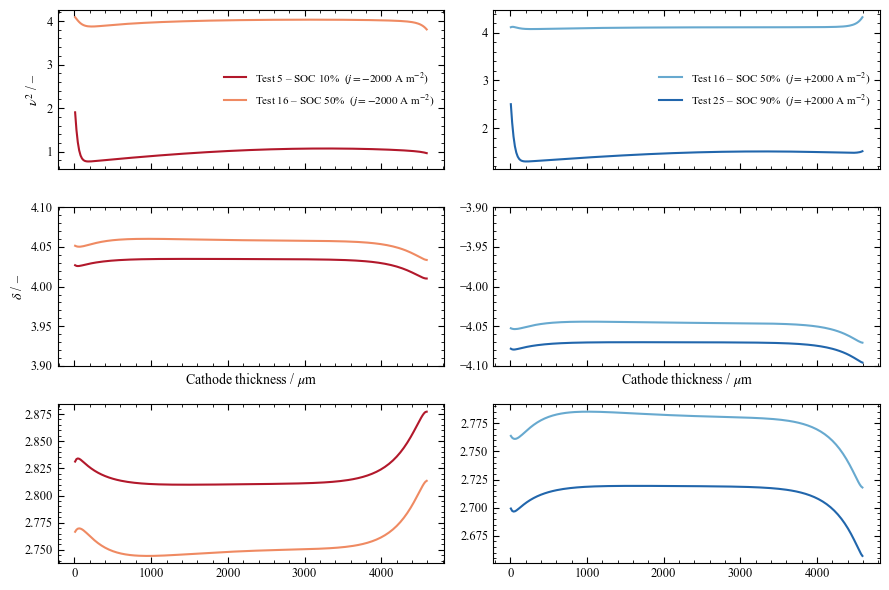

Saved -> C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D\figures\cathode_nu_delta_profiles.pdf


In [ ]:
# -- Porous-electrode dimensionless numbers: nu^2 and delta, 2x2 layout ---------
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['STIX', 'Times New Roman', 'Times'],
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
    'xtick.direction': 'in',
    'ytick.direction': 'in', 
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

fig, axes = plt.subplots(3, 2, figsize=(9, 6), sharex=True)
# axes[0, :] -> nu^2 row (discharge, charge)
# axes[1, :] -> delta row (discharge, charge)
# axes[2, :]  kappa/sigma
for col_idx, (title, cases) in enumerate(_pairs):
    ax_nu    = axes[0, col_idx]
    ax_delta = axes[1, col_idx]
    ax_kappa = axes[2, col_idx]

    legend_handles, legend_labels = [], []

    for test_no, mode, label in cases:
        d   = _cathode_profile_data(test_no, mode)
        col = case_colors[(test_no, mode)]
        (l,) = ax_nu.plot(d["x_um"], d["nu_sq"], color=col, lw=1.5, ls="-")
        ax_delta.plot(d["x_um"], d["delta"], color=col, lw=1.5, ls="-")
        ax_kappa.plot(d["x_um"], d["kappa_io"]/cell.cathode.eff_conductivity, color=col, lw=1.5, ls="-")
        legend_handles.append(l)
        legend_labels.append(f"{label}  ($j={d['j_appl']:+.0f}$ A m$^{{-2}}$)")

    ax_delta.axhline(0, color="0.6", lw=0.5, ls=":")
    ax_delta.set_xlabel(r"Cathode thickness / $\mu$m")

    # Case legend on top-row panels only (avoids redundancy)
    ax_nu.legend(legend_handles, legend_labels, frameon=False, loc="best")


axes[1,0].set_ylim(3.9, 4.1) 
axes[1,1].set_ylim(-4.1, -3.9)

# Y-labels on left column only (since sharey within each row would be appropriate)
axes[0, 0].set_ylabel(r"$\nu^2$ / –")
axes[1, 0].set_ylabel(r"$\delta$ / –")

fig.tight_layout()
out_path = ROOT / "figures" / "cathode_nu_delta_profiles.pdf"
fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()
print(f"Saved -> {out_path}")


In [12]:
print("Effective electronic conductivity:", cell.cathode.eff_conductivity)
print("Effective ionic conductivity:", np.sum(cell.cathode.kappa_io * cell.mesh.cathode_mesh.dx))

Effective electronic conductivity: 64.66652920947598
Effective ionic conductivity: 175.41679788680025


## Cathode overpotential and BV reaction profiles along cathode thickness

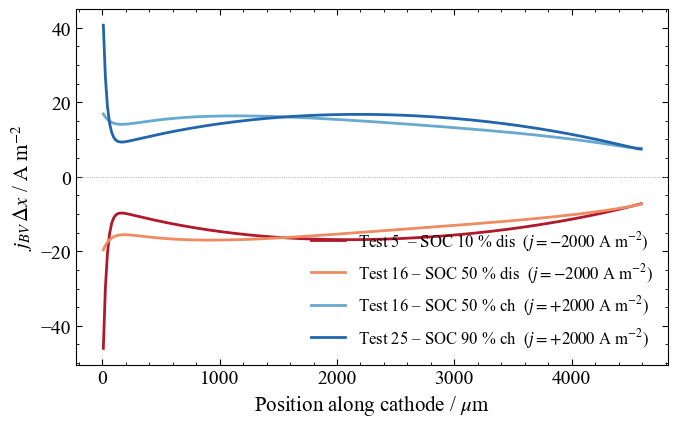

Saved -> C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D\figures\cathode_reaction_profile.pdf


In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size':        14,   # base size
    'axes.labelsize':   15,   # x/y axis labels
    'axes.titlesize':   14,   # subplot titles (if used)
    'xtick.labelsize':  14,   # x tick labels
    'ytick.labelsize':  14,   # y tick labels
    'legend.fontsize':  12,   # legend
})

# Per-(test, mode) colours.
case_colors = {
    (5,  "discharge"): "#b2182b",
    (16, "discharge"): "#ef8a62",
    (16, "charge"):    "#67a9cf",
    (25, "charge"):    "#2166ac",
}

_cases = [
    (5,  "discharge", "Test 5  – SOC 10 % dis"),
    (16, "discharge", "Test 16 – SOC 50 % dis"),
    (16, "charge",    "Test 16 – SOC 50 % ch"),
    (25, "charge",    "Test 25 – SOC 90 % ch"),
]

fig, ax = plt.subplots(figsize=(7, 4.5))

legend_handles, legend_labels = [], []

for test_no, mode, label in _cases:
    col  = case_colors[(test_no, mode)]
    r    = results[test_no, mode]
    cell = r["cell"]
    y    = r["y"]

    dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6

    decomp = cell.decompose_overpotential(y)
    state  = cell.split_state(y)
    c_cat  = np.concatenate([state["cathode"][:, 0],
                             state["cathode"][:, 1],
                             state["cathode"][:, 2]])
    bv_dx  = cell.butler_volmer(decomp["eta_total"], c_cat, "cathode") * dx_ca

    j_appl = r["j_appl"]
    (l,) = ax.plot(x_um, bv_dx, color=col, lw=2)

    legend_handles.append(l)
    legend_labels.append(f"{label}  ($j={j_appl:+.0f}$ A m$^{{-2}}$)")

ax.axhline(0, color="0.6", lw=0.6, ls=":")
ax.set_xlabel(r"Position along cathode / $\mu$m")
ax.set_ylabel(r"$j_{BV}\,\Delta x$ / A m$^{-2}$")
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.legend(legend_handles, legend_labels,
          frameon=False, loc="best")   # ← removed fontsize=8 so it inherits from rcParams

fig.tight_layout()

out_path = ROOT / "figures/cathode_reaction_profile.pdf"
fig.savefig(out_path, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_path}")

## Ionic and electronic current density along cathode thickness

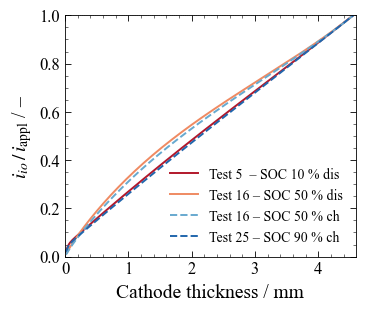

Saved -> C:\Users\jbvba\MSC RFB\RFBmodel1D_PC\rfbmodel1D\figures\cathode_current_density_profiles.pdf


In [14]:
from rfbmodel1D.parameters.params import Vars

# -- Elsevier two-column figure style ------------------------------------------
plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset":  "stix",
    "font.size":         10,
    "axes.labelsize":    14,
    "axes.titlesize":    10,
    "xtick.labelsize":   12,
    "ytick.labelsize":   12,
    "legend.fontsize":   10,
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "lines.linewidth":   1.2,
    "savefig.dpi":       600,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

# Per-(test, mode) colours.
# Discharge -> red family (lighter = closer to mid-SOC)
# Charge    -> blue family (lighter = closer to mid-SOC)
case_colors = {
    (5,  "discharge"): "#b2182b",   # deep red    (extreme: SOC 10%)
    (16, "discharge"): "#ef8a62",   # light red   (mid: SOC 50%)
    (16, "charge"):    "#67a9cf",   # light blue  (mid: SOC 50%)
    (25, "charge"):    "#2166ac",   # deep blue   (extreme: SOC 90%)
}

# Test 16 -> dashed; the SOC extremes -> solid
case_linestyles = {
    (5,  "discharge"): "-",
    (16, "discharge"): "-",
    (16, "charge"):    "--",
    (25, "charge"):    "--",
}

_cases_curr = [
    (5,  "discharge", "Test 5  – SOC 10 % dis"),
    (16, "discharge", "Test 16 – SOC 50 % dis"),
    (16, "charge",    "Test 16 – SOC 50 % ch"),
    (25, "charge",    "Test 25 – SOC 90 % ch"),
]

# Elsevier single-column width is 90 mm (~3.54"); two-column is 190 mm (~7.48").
# This is a single-column figure.
fig, ax = plt.subplots(figsize=(3.54, 3.0))

for test_no, mode, label in _cases_curr:
    col    = case_colors[(test_no, mode)]
    ls     = case_linestyles[(test_no, mode)]
    r      = results[test_no, mode]
    cell   = r["cell"]
    y      = r["y"]
    j_appl = r["j_appl"]

    # -- state extraction ------------------------------------------------------
    Nc     = cell.mesh.cathode_mesh.n_x
    n_ca   = cell.layout.n_vars_cathode
    off_ca = cell.layout.n_vars_tank

    y_ca   = y[off_ca : off_ca + Nc * n_ca].reshape(Nc, n_ca)
    phi_s  = y_ca[:, 4]   # electronic (solid) potential
    phi_l  = y_ca[:, 5]   # ionic (liquid) potential

    kappa  = cell.cathode.kappa_io
    sigma  = float(cell.cathode.eff_conductivity)

    # -- node centres [µm] -----------------------------------------------------
    dx_ca  = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    edges  = np.concatenate([[0.0], np.cumsum(dx_ca)])
    x_ctr  = 0.5 * (edges[:-1] + edges[1:])
    x_um   = x_ctr * 1e3

    # -- Ionic current density profile ----------------------------------------
    dx_face = x_ctr[1:] - x_ctr[:-1]
    g_io    = (phi_l[1:] - phi_l[:-1]) / dx_face

    i_io = np.empty(Nc)
    i_io[0]    = -kappa[0]    * g_io[0]
    i_io[1:-1] = -kappa[1:-1] * 0.5 * (g_io[:-1] + g_io[1:])
    i_io[-1]   = -kappa[-1]   * g_io[-1]

    ax.plot(x_um, i_io / j_appl, color=col, lw=1.4, ls=ls, label=label)


# -- Formatting ----------------------------------------------------------------
ax.axhline(0, color="0.6", lw=0.5, ls=":")
ax.axhline(1, color="0.6", lw=0.5, ls=":")
ax.set_xlabel(r"Cathode thickness / mm")
ax.set_ylabel(r"$i_{io} \,/\, i_{\mathrm{appl}}$ / –")
ax.set_ylim(0, 1)
ax.set_xlim(0, x_um[-1])
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.legend(frameon=False, loc="best")

fig.tight_layout(pad=0.3)

out_path = ROOT / "figures/cathode_current_density_profiles.pdf"
fig.savefig(out_path, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_path}")


## Surface and bulk concentrations along cathode thickness

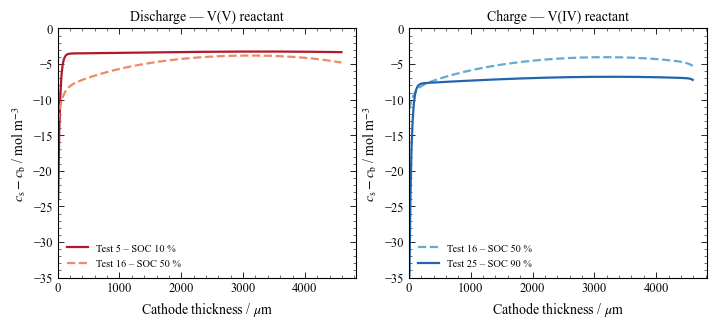

In [21]:
from rfbmodel1D.electrochem.butler_volmer import cathode_surface_concentrations

case_colors = {
    (5,  "discharge"): "#b2182b",
    (16, "discharge"): "#ef8a62",
    (16, "charge"):    "#67a9cf",
    (25, "charge"):    "#2166ac",
}
case_ls = {
    (5,  "discharge"): "-",
    (16, "discharge"): "--",
    (16, "charge"):    "--",
    (25, "charge"):    "-",
}

_dis_cases = [(5,  "discharge", "Test 5 – SOC 10 %"),
              (16, "discharge", "Test 16 – SOC 50 %")]
_ch_cases  = [(16, "charge",   "Test 16 – SOC 50 %"),
              (25, "charge",   "Test 25 – SOC 90 %")]

fig, (ax_dis, ax_ch) = plt.subplots(1, 2, figsize=(7.08, 3.2), sharey=False)

for ax, mode_cases, title, species_label in [
    (ax_dis, _dis_cases, "Discharge — V(V) reactant", "V(V)"),
    (ax_ch,  _ch_cases,  "Charge — V(IV) reactant",   "V(IV)"),
]:
    for test_no, mode, label in mode_cases:
        col = case_colors[(test_no, mode)]
        ls  = case_ls[(test_no, mode)]
        r   = results[test_no, mode]
        cell, y = r["cell"], r["y"]

        Nc     = cell.mesh.cathode_mesh.n_x
        n_ca   = cell.layout.n_vars_cathode
        off_ca = cell.layout.n_vars_tank
        y_ca   = y[off_ca : off_ca + Nc * n_ca].reshape(Nc, n_ca)
        c_V4_ca, c_V5_ca, c_H_ca = y_ca[:, 0], y_ca[:, 1], y_ca[:, 2]
        Phi_el_ca, Phi_io_ca      = y_ca[:, 4], y_ca[:, 5]

        c_eta = np.concatenate([c_V4_ca, c_V5_ca, c_H_ca])
        cell.compute_overpotential(Phi_el_ca, Phi_io_ca, c_eta, "cathode")
        eta = cell.cathode.eta
        c_s_V4, c_s_V5, *_ = cathode_surface_concentrations(cell, eta, c_V4_ca, c_V5_ca)

        dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
        x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6

        if mode == "discharge":
            delta_c = c_s_V5 - c_V5_ca   # negative = surface depletion
        else:
            delta_c = c_s_V4 - c_V4_ca

        ax.plot(x_um, delta_c, color=col, ls=ls, lw=1.6, label=label)

    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    ax.set_xlabel(r"Cathode thickness / $\mu$m")
    ax.set_ylabel(r"$c_\mathrm{s} - c_\mathrm{b}$ / mol m$^{-3}$")
    ax.set_title(title)
    ax.set_ylim(-35,0)
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.set_xlim(left=0)
    ax.legend(frameon=False, fontsize=7.5)

fig.tight_layout(pad=0.4)
out_path = ROOT / "figures/cathode_concentration_difference_profiles.pdf"
#fig.savefig(out_path, bbox_inches="tight")
plt.show()
#print(f"Saved -> {out_path}")

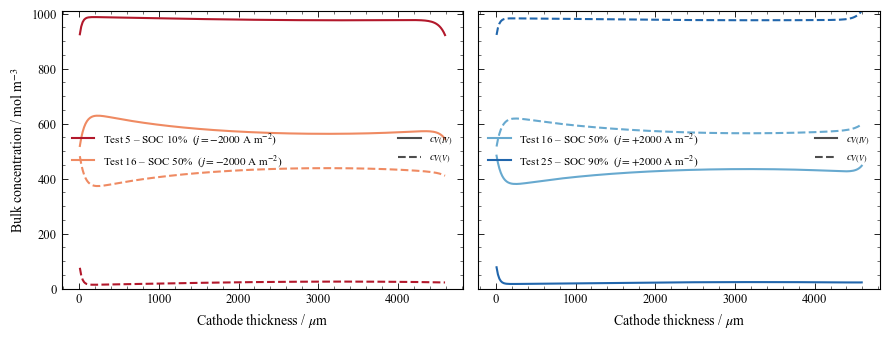

In [24]:
# -- Cathode bulk concentrations (V(IV), V(V)) ----------------------------------
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import ticker

# Paper style — set once
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['STIX', 'Times New Roman', 'Times'],
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

species_ls = {"V4": "-", "V5": "--"}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

for ax, (title, cases) in zip(axes, _pairs):
    legend_handles, legend_labels = [], []

    for test_no, mode, label in cases:
        d   = _cathode_profile_data(test_no, mode)
        col = case_colors[(test_no, mode)]
        (l,) = ax.plot(d["x_um"], d["c_V4"], color=col, lw=1.5, ls=species_ls["V4"])
        ax.plot(d["x_um"], d["c_V5"], color=col, lw=1.5, ls=species_ls["V5"])
        legend_handles.append(l)
        legend_labels.append(f"{label}  ($j={d['j_appl']:+.0f}$ A m$^{{-2}}$)")

    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    ax.set_xlabel(r"Cathode thickness / $\mu$m")

    case_legend = ax.legend(legend_handles, legend_labels, frameon=False, loc="center left")
    ax.add_artist(case_legend)
    style_handles = [
        Line2D([0], [0], color="0.3", lw=1.5, ls=species_ls["V4"], label=r"$c_{V(IV)}$"),
        Line2D([0], [0], color="0.3", lw=1.5, ls=species_ls["V5"], label=r"$c_{V(V)}$"),
    ]
    ax.legend(handles=style_handles, frameon=False, loc="center right")

# Shared y-axis label on the left panel only (since sharey=True)
axes[0].set_ylabel(r"Bulk concentration / mol m$^{-3}$")
axes[0].set_ylim(0, 1.01e3)

fig.tight_layout()
out_path = ROOT / "figures" / "cathode_concentrations.pdf"
#fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()
#print(f"Saved -> {out_path}")

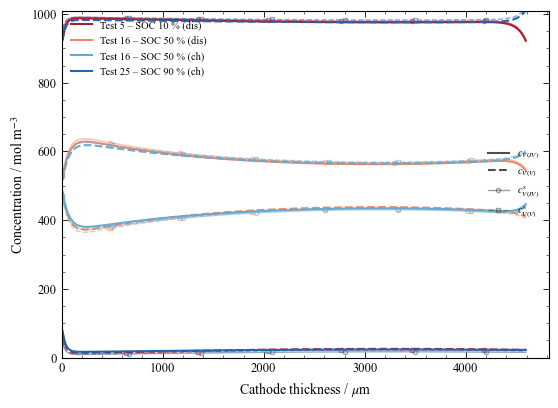

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import ticker
from rfbmodel1D.electrochem.butler_volmer import cathode_surface_concentrations


def _cathode_profile_data(test_no, mode):
    """Bulk + surface concentrations and x-grid for one case."""
    r = results[test_no, mode]
    cell, y = r["cell"], r["y"]

    Nc     = cell.mesh.cathode_mesh.n_x
    n_ca   = cell.layout.n_vars_cathode
    off_ca = cell.layout.n_vars_tank
    y_ca   = y[off_ca : off_ca + Nc * n_ca].reshape(Nc, n_ca)

    c_V4, c_V5, c_H = y_ca[:, 0], y_ca[:, 1], y_ca[:, 2]
    Phi_el, Phi_io  = y_ca[:, 4], y_ca[:, 5]

    c_eta = np.concatenate([c_V4, c_V5, c_H])
    cell.compute_overpotential(Phi_el, Phi_io, c_eta, "cathode")
    c_s_V4, c_s_V5, *_ = cathode_surface_concentrations(
        cell, cell.cathode.eta, c_V4, c_V5)

    dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    x_um  = (np.cumsum(dx_ca) - dx_ca / 2) * 1e6

    return dict(x_um=x_um, c_V4=c_V4, c_V5=c_V5,
                c_s_V4=c_s_V4, c_s_V5=c_s_V5,
                j_appl=r.get("j_appl", np.nan))


# -- single panel: V(IV) and V(V), bulk and surface ----------------------------
species_ls = {"V4": "-", "V5": "--"}
all_cases  = [(t, m, f"{lab} ({'dis' if m == 'discharge' else 'ch'})")
              for (t, m, lab) in _dis_cases + _ch_cases]

fig, ax = plt.subplots(figsize=(5.5, 4.0))

legend_handles, legend_labels = [], []
for test_no, mode, label in all_cases:
    d   = _cathode_profile_data(test_no, mode)
    col = case_colors[(test_no, mode)]

    (l,) = ax.plot(d["x_um"], d["c_V4"], color=col, lw=1.5, ls=species_ls["V4"])
    ax.plot(d["x_um"], d["c_V5"], color=col, lw=1.5, ls=species_ls["V5"])

    ax.plot(d["x_um"], d["c_s_V4"], color=col, lw=1.0, ls=species_ls["V4"],
            alpha=0.55, marker="o", markevery=0.12, ms=3, mfc="none")
    ax.plot(d["x_um"], d["c_s_V5"], color=col, lw=1.0, ls=species_ls["V5"],
            alpha=0.55, marker="s", markevery=0.12, ms=3, mfc="none")

    legend_handles.append(l)
    legend_labels.append(label)

ax.set_xlabel(r"Cathode thickness / $\mu$m")
ax.set_ylabel(r"Concentration / mol m$^{-3}$")
ax.set_xlim(left=0)
ax.set_ylim(0, 1.01e3)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

case_legend = ax.legend(legend_handles, legend_labels,
                        frameon=False, fontsize=7.5, loc="upper left")
ax.add_artist(case_legend)

style_handles = [
    Line2D([0], [0], color="0.3", lw=1.5, ls="-",  label=r"$c_{V(IV)}$"),
    Line2D([0], [0], color="0.3", lw=1.5, ls="--", label=r"$c_{V(V)}$"),
    Line2D([0], [0], color="0.3", lw=1.0, ls="-",  alpha=0.55,
           marker="o", ms=3, mfc="none", label=r"$c^{\mathrm{s}}_{V(IV)}$"),
    Line2D([0], [0], color="0.3", lw=1.0, ls="--", alpha=0.55,
           marker="s", ms=3, mfc="none", label=r"$c^{\mathrm{s}}_{V(V)}$"),
]
ax.legend(handles=style_handles, frameon=False, fontsize=7.5, loc="center right")

fig.tight_layout(pad=0.4)
out_path = ROOT / "figures/cathode_concentrations.pdf"
# fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()

Test 5 – SOC 10 % (dis, V(V))        bulk [   14.0,    75.6]   surf [   10.4,    51.6]
Test 16 – SOC 50 % (dis, V(V))       bulk [  372.8,   481.6]   surf [  364.9,   468.6]
Test 16 – SOC 50 % (ch, V(IV))       bulk [  380.4,   483.3]   surf [  372.5,   471.9]
Test 25 – SOC 90 % (ch, V(IV))       bulk [   16.7,    77.5]   surf [    9.0,    42.7]


C:\Users\jbvba\AppData\Local\Temp\ipykernel_39776\3812635794.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.4)


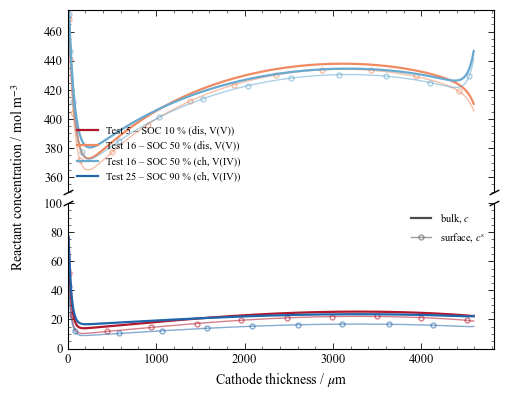

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import ticker

reactant = {"discharge": "V5", "charge": "V4"}      # species of interest per mode
sp_tex   = {"V4": r"V(IV)", "V5": r"V(V)"}

all_cases = [(t, m, f"{lab} ({'dis' if m == 'discharge' else 'ch'}, "
                    f"{sp_tex[reactant[m]]})")
             for (t, m, lab) in _dis_cases + _ch_cases]

data = {(t, m): _cathode_profile_data(t, m) for t, m, _ in all_cases}

# --- check the ranges before fixing the bands --------------------------------
for t, m, lab in all_cases:
    sp, d = reactant[m], data[(t, m)]
    print(f"{lab:36s} bulk [{d[f'c_{sp}'].min():7.1f}, {d[f'c_{sp}'].max():7.1f}]"
          f"   surf [{d[f'c_s_{sp}'].min():7.1f}, {d[f'c_s_{sp}'].max():7.1f}]")

bands   = [(350, 475), (0, 100)]                    # top -> bottom; edit from print
heights = [hi - lo for lo, hi in bands]

fig, axs = plt.subplots(len(bands), 1, sharex=True, figsize=(5.5, 4.4),
                        gridspec_kw=dict(height_ratios=heights, hspace=0.07))

legend_handles, legend_labels = [], []
for ax in axs:
    for test_no, mode, label in all_cases:
        d, col, sp = data[(test_no, mode)], case_colors[(test_no, mode)], reactant[mode]
        (l,) = ax.plot(d["x_um"], d[f"c_{sp}"], color=col, lw=1.6, ls="-")
        ax.plot(d["x_um"], d[f"c_s_{sp}"], color=col, lw=1.0, ls="-",
                alpha=0.55, marker="o", markevery=0.10, ms=3.5, mfc="none")
        if ax is axs[0]:
            legend_handles.append(l)
            legend_labels.append(label)
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

for ax, (lo, hi) in zip(axs, bands):
    ax.set_ylim(lo, hi)

brk = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=7, linestyle="none",
           color="k", mec="k", mew=1, clip_on=False)
for upper, lower in zip(axs[:-1], axs[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(which="both", bottom=False, labelbottom=False)
    lower.tick_params(which="both", top=False)
    upper.plot([0, 1], [0, 0], transform=upper.transAxes, **brk)
    lower.plot([0, 1], [1, 1], transform=lower.transAxes, **brk)

axs[-1].set_xlabel(r"Cathode thickness / $\mu$m")
axs[-1].set_xlim(left=0)
axs[-1].xaxis.set_minor_locator(ticker.AutoMinorLocator())
fig.supylabel(r"Reactant concentration / mol m$^{-3}$", fontsize=10)

axs[0].legend(legend_handles, legend_labels, frameon=False,
              fontsize=7.5, loc="lower left")

style_handles = [
    Line2D([0], [0], color="0.3", lw=1.6, ls="-", label="bulk, $c$"),
    Line2D([0], [0], color="0.3", lw=1.0, ls="-", alpha=0.55,
           marker="o", ms=3.5, mfc="none", label=r"surface, $c^{\mathrm{s}}$"),
]
axs[-1].legend(handles=style_handles, frameon=False, fontsize=7.5,
               loc="upper right")

fig.tight_layout(pad=0.4)
out_path = ROOT / "figures/cathode_reactant_concentrations.pdf"
# fig.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()